In [1]:
# Import Libraries and load dataset
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

OUTPUT_DIR = Path("car_price_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    OUTPUT_DIR / "car_data_cleaned.csv"
)

print("Dataset shape:", df.shape)
print("\nAvailable features:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (299, 9)

Available features:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
# Define the target and input features
if "Car_Age" not in df.columns:
    df["Car_Age"] = 2018 - df["Year"]

if "Mileage_Per_Year" not in df.columns:
    df["Mileage_Per_Year"] = np.where(
        df["Car_Age"] > 0,
        df["Driven_kms"] / df["Car_Age"],
        np.nan
    )

# Define target
target = "Selling_Price"

# Define candidate predictors
numeric_features = [
    "Present_Price",
    "Driven_kms",
    "Car_Age",
    "Mileage_Per_Year",
    "Owner"
]

categorical_features = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

feature_columns = numeric_features + categorical_features

# Validate required columns
required_columns = feature_columns + [target]
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Create X and y
X = df[feature_columns].copy()
y = df[target].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

display(X.head())
display(y.head())

Feature matrix shape: (299, 9)
Target shape: (299,)

Numerical features:
['Present_Price', 'Driven_kms', 'Car_Age', 'Mileage_Per_Year', 'Owner']

Categorical features:
['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']


,Present_Price,Driven_kms,Car_Age,Mileage_Per_Year,Owner,Car_Name,Fuel_Type,Selling_type,Transmission
0,5.59,27000,4,6750.000000,0,ritz,Petrol,Dealer,Manual
1,9.54,43000,5,8600.000000,0,sx4,Diesel,Dealer,Manual
2,9.85,6900,1,6900.000000,0,ciaz,Petrol,Dealer,Manual
3,4.15,5200,7,742.857143,0,wagon r,Petrol,Dealer,Manual
4,6.87,42450,4,10612.500000,0,swift,Diesel,Dealer,Manual


,Selling_Price
0,3.35
1,4.75
2,7.25
3,2.85
4,4.60


In [3]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print(
    f"\nTraining proportion: "
    f"{len(X_train) / len(X):.1%}"
)

print(
    f"Testing proportion: "
    f"{len(X_test) / len(X):.1%}"
)

Training features: (239, 9)
Testing features: (60, 9)
Training targets: (239,)
Testing targets: (60,)

Training proportion: 79.9%
Testing proportion: 20.1%


In [4]:
# Build the preprocessing pipeline
# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [5]:
# Fit preprocessing on training data only
# Learn imputation values, scaling parameters,
# and categorical encoding from training data
X_train_processed = preprocessor.fit_transform(
    X_train
)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(
    X_test
)

print(
    "Processed training shape:",
    X_train_processed.shape
)

print(
    "Processed testing shape:",
    X_test_processed.shape
)

print(
    "Sparse training matrix:",
    hasattr(X_train_processed, "toarray")
)

Processed training shape: (239, 97)
Processed testing shape: (60, 97)
Sparse training matrix: True


In [6]:
# Inspect the transformed features
feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))

print("\nFirst 30 transformed feature names:")
print(feature_names[:30])

Number of transformed features: 97

First 30 transformed feature names:
['num__Present_Price' 'num__Driven_kms' 'num__Car_Age'
 'num__Mileage_Per_Year' 'num__Owner' 'cat__Car_Name_800'
 'cat__Car_Name_Activa 3g' 'cat__Car_Name_Activa 4g'
 'cat__Car_Name_Bajaj  ct 100' 'cat__Car_Name_Bajaj Avenger 150'
 'cat__Car_Name_Bajaj Avenger 150 street'
 'cat__Car_Name_Bajaj Avenger 220' 'cat__Car_Name_Bajaj Avenger 220 dtsi'
 'cat__Car_Name_Bajaj Avenger Street 220'
 'cat__Car_Name_Bajaj Discover 100' 'cat__Car_Name_Bajaj Discover 125'
 'cat__Car_Name_Bajaj Dominar 400' 'cat__Car_Name_Bajaj Pulsar  NS 200'
 'cat__Car_Name_Bajaj Pulsar 135 LS' 'cat__Car_Name_Bajaj Pulsar 150'
 'cat__Car_Name_Bajaj Pulsar 220 F' 'cat__Car_Name_Bajaj Pulsar NS 200'
 'cat__Car_Name_Hero  CBZ Xtreme' 'cat__Car_Name_Hero  Ignitor Disc'
 'cat__Car_Name_Hero Extreme' 'cat__Car_Name_Hero Hunk'
 'cat__Car_Name_Hero Passion Pro' 'cat__Car_Name_Hero Passion X pro'
 'cat__Car_Name_Hero Splender Plus' 'cat__Car_Name_Hero Sple

In [7]:
# Save the training and testing splits
# Save raw feature splits before encoding
X_train.to_csv(
    OUTPUT_DIR / "X_train.csv",
    index=False
)

X_test.to_csv(
    OUTPUT_DIR / "X_test.csv",
    index=False
)

y_train.to_csv(
    OUTPUT_DIR / "y_train.csv",
    index=False
)

y_test.to_csv(
    OUTPUT_DIR / "y_test.csv",
    index=False
)

print("Training and testing splits saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

Training and testing splits saved successfully.
Output directory: /content/car_price_outputs


In [8]:
# Final preparation checks
print("FINAL MACHINE-LEARNING DATA CHECK")
print("=" * 45)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("Training target missing:", y_train.isna().sum())
print("Testing target missing:", y_test.isna().sum())

print(
    "Processed training contains non-finite values:",
    not np.isfinite(
        X_train_processed.toarray()
        if hasattr(X_train_processed, "toarray")
        else X_train_processed
    ).all()
)

print(
    "Processed testing contains non-finite values:",
    not np.isfinite(
        X_test_processed.toarray()
        if hasattr(X_test_processed, "toarray")
        else X_test_processed
    ).all()
)

FINAL MACHINE-LEARNING DATA CHECK
Training rows: 239
Testing rows: 60
Training target missing: 0
Testing target missing: 0
Processed training contains non-finite values: False
Processed testing contains non-finite values: False


In [9]:
# Ensure the target column exists
target = "Selling_Price"
if target not in df.columns:
    raise ValueError(f"Target column '{target}' was not found.")

# Remove rows where the target is missing
df = df.dropna(subset=[target]).copy()

# Create engineered features if they do not already exist
if "Car_Age" not in df.columns:
    df["Car_Age"] = 2018 - df["Year"]

if "Mileage_Per_Year" not in df.columns:
    df["Mileage_Per_Year"] = (
        df["Driven_kms"] / df["Car_Age"].replace(0, np.nan)
    )

numeric_features = [
    "Present_Price",
    "Driven_kms",
    "Car_Age",
    "Mileage_Per_Year",
    "Owner"
]

categorical_features = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

# Keep only features available in this dataset
numeric_features = [c for c in numeric_features if c in df.columns]
categorical_features = [c for c in categorical_features if c in df.columns]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df[target].astype(float).copy()

# Ensure numeric feature columns contain numeric values
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Use a consistent split for every model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset shape:", df.shape)
print("Number of features:", len(feature_columns))
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("\nFeatures used:", feature_columns)

Dataset shape: (299, 11)
Number of features: 9
Training samples: 239
Testing samples: 60

Features used: ['Present_Price', 'Driven_kms', 'Car_Age', 'Mileage_Per_Year', 'Owner', 'Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']


In [10]:
# Build preprocessing and model pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    for name, model in models.items()
}

print("Created", len(pipelines), "model pipelines.")


Created 4 model pipelines.


In [11]:
# Train, cross-validate, and evaluate
results = []
trained_models = {}
predictions = {}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, pipeline in pipelines.items():
    print(f"Training {name}...")

    # Cross-validation is performed using training data only
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=1
    )

    cv_rmse = np.sqrt(-cv_scores).mean()

    # Fit on the full training set
    pipeline.fit(X_train, y_train)

    # Evaluate once on the held-out test set
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "CV_RMSE": cv_rmse,
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "Test_R2": r2
    })

    trained_models[name] = pipeline
    predictions[name] = y_pred

results_df = pd.DataFrame(results).sort_values("Test_RMSE")

print("\nModel Comparison:")
display(results_df.round(4))

results_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

print(f"Results saved to: {OUTPUT_DIR / 'model_comparison.csv'}")


Training Linear Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

Model Comparison:


,Model,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression,1.5878,1.4342,2.7120,0.7146
3,Gradient Boosting,1.5740,1.2915,3.1271,0.6206
1,Decision Tree,2.2666,1.3608,3.2031,0.6019
2,Random Forest,1.5110,1.4633,3.5790,0.5030


Results saved to: car_price_outputs/model_comparison.csv


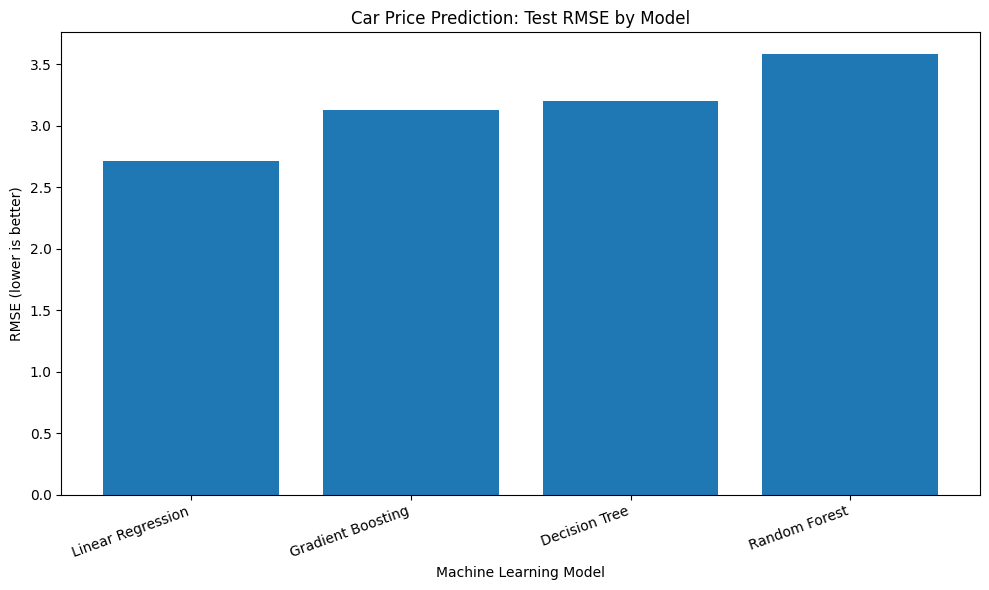

In [12]:
# model performance

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(results_df["Model"], results_df["Test_RMSE"])
plt.title("Car Price Prediction: Test RMSE by Model")
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


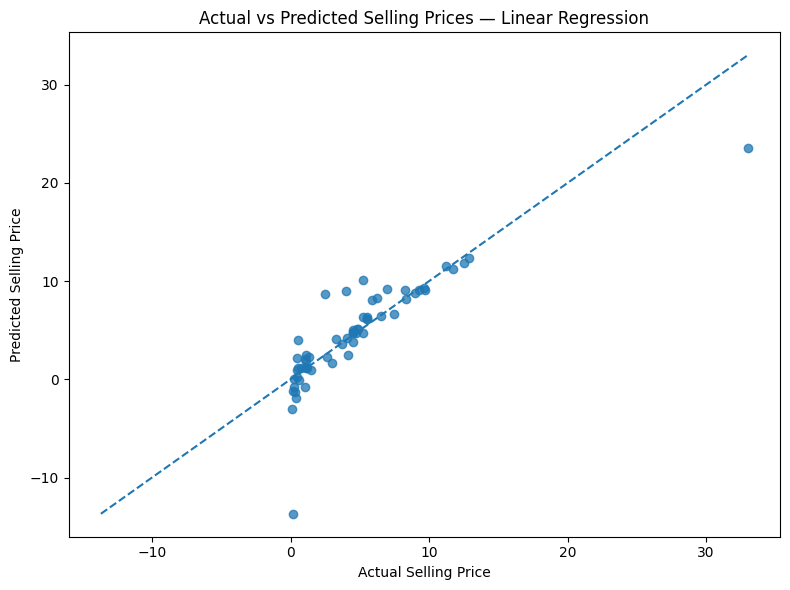

Best model by test RMSE: Linear Regression
Plots saved in: /content/car_price_outputs


In [13]:
# Compare actual and predicted prices

best_model_name = results_df.iloc[0]["Model"]
best_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.75)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Selling Prices — {best_model_name}")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Best model by test RMSE:", best_model_name)
print("Plots saved in:", OUTPUT_DIR.resolve())


In [14]:
# Save actual and predicted values

prediction_df = pd.DataFrame({
    "Actual_Selling_Price": y_test.to_numpy(),
    "Predicted_Selling_Price": best_predictions,
})

prediction_df["Prediction_Error"] = (
    prediction_df["Actual_Selling_Price"]
    - prediction_df["Predicted_Selling_Price"]
)

prediction_df.to_csv(
    OUTPUT_DIR / "best_model_predictions.csv",
    index=False
)

print(prediction_df.head(10))
print("\nSaved predictions to:",
      (OUTPUT_DIR / "best_model_predictions.csv").resolve())


   Actual_Selling_Price  Predicted_Selling_Price  Prediction_Error
0                  8.99                 8.752338          0.237662
1                  8.35                 8.144332          0.205668
2                  0.45                 0.944707         -0.494707
3                  7.45                 6.640189          0.809811
4                  5.25                10.161038         -4.911038
5                  5.25                 4.768970          0.481030
6                  5.85                 8.120565         -2.270565
7                  1.15                 2.500871         -1.350871
8                  9.25                 9.144608          0.105392
9                  0.38                -1.930686          2.310686

Saved predictions to: /content/car_price_outputs/best_model_predictions.csv


**Hyperparameter Tuning: Random Forest and Gradient Boosting**

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 239
Testing samples: 60


In [18]:
# Import clone from sklearn.base
from sklearn.base import clone

# Define the hyperparameter search spaces

# Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_param_grid = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 8, 12, 15, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": [1.0, "sqrt", 0.7]
}

# Gradient Boosting pipeline
gb_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", GradientBoostingRegressor(
        random_state=42
    ))
])

gb_param_grid = {
    "model__n_estimators": [50, 100, 150, 200, 300],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.15],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__max_features": [None, "sqrt", 0.7]
}

print("Random Forest candidate combinations:",
      np.prod([len(v) for v in rf_param_grid.values()]))

print("Gradient Boosting candidate combinations:",
      np.prod([len(v) for v in gb_param_grid.values()]))

Random Forest candidate combinations: 1152
Gradient Boosting candidate combinations: 19200


In [19]:
# Tune Random Forest
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=25,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

rf_search.fit(X_train, y_train)

print("\nBest Random Forest CV RMSE:",
      round(-rf_search.best_score_, 4))

print("\nBest Random Forest parameters:")
for param, value in rf_search.best_params_.items():
    print(f"{param}: {value}")


Fitting 5 folds for each of 25 candidates, totalling 125 fits

Best Random Forest CV RMSE: 1.5839

Best Random Forest parameters:
model__n_estimators: 100
model__min_samples_split: 10
model__min_samples_leaf: 1
model__max_features: 1.0
model__max_depth: 12


In [20]:
# Tune Gradient Boosting
gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_grid,
    n_iter=25,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

gb_search.fit(X_train, y_train)

print("\nBest Gradient Boosting CV RMSE:",
      round(-gb_search.best_score_, 4))

print("\nBest Gradient Boosting parameters:")
for param, value in gb_search.best_params_.items():
    print(f"{param}: {value}")


Fitting 5 folds for each of 25 candidates, totalling 125 fits

Best Gradient Boosting CV RMSE: 1.3662

Best Gradient Boosting parameters:
model__subsample: 0.9
model__n_estimators: 50
model__min_samples_split: 15
model__min_samples_leaf: 1
model__max_features: 0.7
model__max_depth: 5
model__learning_rate: 0.15


In [21]:
# Evaluate the tuned models

candidate_models = {
    "Linear Regression (Baseline)": trained_models["Linear Regression"],
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "Gradient Boosting (Tuned)": gb_search.best_estimator_
}

tuning_results = []
tuned_predictions = {}

for name, model in candidate_models.items():
    y_pred = model.predict(X_test)
    tuned_predictions[name] = y_pred

    tuning_results.append({
        "Model": name,
        "CV_RMSE": (
            -rf_search.best_score_
            if name == "Random Forest (Tuned)"
            else -gb_search.best_score_
            if name == "Gradient Boosting (Tuned)"
            else np.nan
        ),
        "Test_MAE": mean_absolute_error(y_test, y_pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Test_R2": r2_score(y_test, y_pred)
    })

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values("Test_RMSE")

display(tuning_results_df.round(4))

tuning_results_df.to_csv(
    OUTPUT_DIR / "tuned_model_comparison.csv",
    index=False
)

print("Saved to:", (OUTPUT_DIR / "tuned_model_comparison.csv").resolve())


,Model,CV_RMSE,Test_MAE,Test_RMSE,Test_R2
0,Linear Regression (Baseline),NaN,1.4342,2.7120,0.7146
2,Gradient Boosting (Tuned),1.3662,1.1845,2.9670,0.6584
1,Random Forest (Tuned),1.5839,1.6303,4.0671,0.3582


Saved to: /content/car_price_outputs/tuned_model_comparison.csv


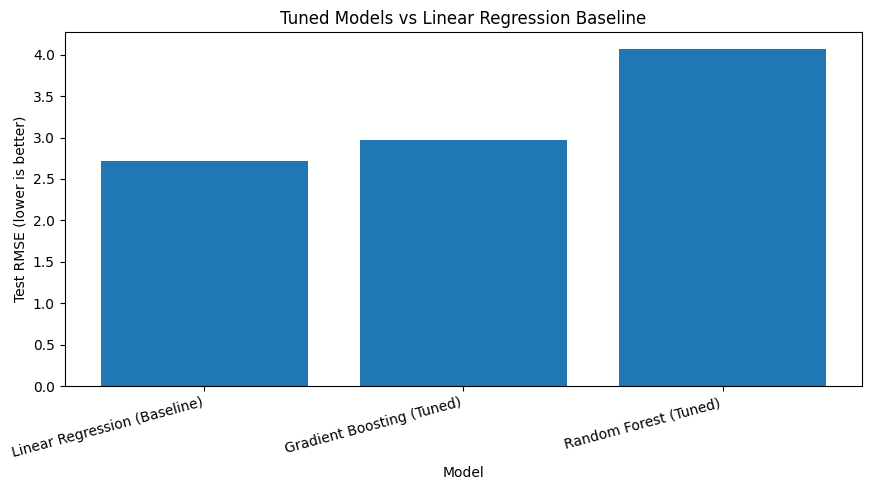

In [22]:
# Visualize the tuned model comparison
plt.figure(figsize=(9, 5))

plt.bar(
    tuning_results_df["Model"],
    tuning_results_df["Test_RMSE"]
)

plt.title("Tuned Models vs Linear Regression Baseline")
plt.xlabel("Model")
plt.ylabel("Test RMSE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "tuned_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:
# Save the best tuned model

import joblib

searches = {
    "Random Forest": rf_search,
    "Gradient Boosting": gb_search
}

best_tuned_name = min(
    searches,
    key=lambda name: searches[name].best_score_
)

best_tuned_model = searches[best_tuned_name].best_estimator_

model_path = OUTPUT_DIR / "best_tuned_car_price_model.joblib"
joblib.dump(best_tuned_model, model_path)

print("Best tuned model by cross-validation:", best_tuned_name)
print("Best CV RMSE:", round(
    -searches[best_tuned_name].best_score_, 4
))
print("Model saved to:", model_path.resolve())


Best tuned model by cross-validation: Random Forest
Best CV RMSE: 1.5839
Model saved to: /content/car_price_outputs/best_tuned_car_price_model.joblib


In [24]:
# Analyze residuals
# Use the Linear Regression baseline
final_model = trained_models["Linear Regression"]
y_pred = final_model.predict(X_test)

residuals = np.asarray(y_test) - y_pred

print("Final evaluation — Linear Regression")
print(f"MAE:  {mean_absolute_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R²:   {r2_score(y_test, y_pred):.4f}")
print(f"Mean residual: {residuals.mean():.4f}")

residual_df = pd.DataFrame({
    "Actual_Price": np.asarray(y_test),
    "Predicted_Price": y_pred,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
}).sort_values("Absolute_Error", ascending=False)

display(residual_df.head(10))

residual_df.to_csv(
    OUTPUT_DIR / "linear_regression_residual_analysis.csv",
    index=False
)


Final evaluation — Linear Regression
MAE:  1.4342
RMSE: 2.7120
R²:   0.7146
Mean residual: 0.0792


,Actual_Price,Predicted_Price,Residual,Absolute_Error
37,0.17,-13.688622,13.858622,13.858622
18,33.00,23.571975,9.428025,9.428025
52,2.50,8.737108,-6.237108,6.237108
39,4.00,8.967573,-4.967573,4.967573
4,5.25,10.161038,-4.911038,4.911038
16,0.51,3.958076,-3.448076,3.448076
45,0.12,-3.035781,3.155781,3.155781
9,0.38,-1.930686,2.310686,2.310686
59,6.95,9.225884,-2.275884,2.275884
6,5.85,8.120565,-2.270565,2.270565


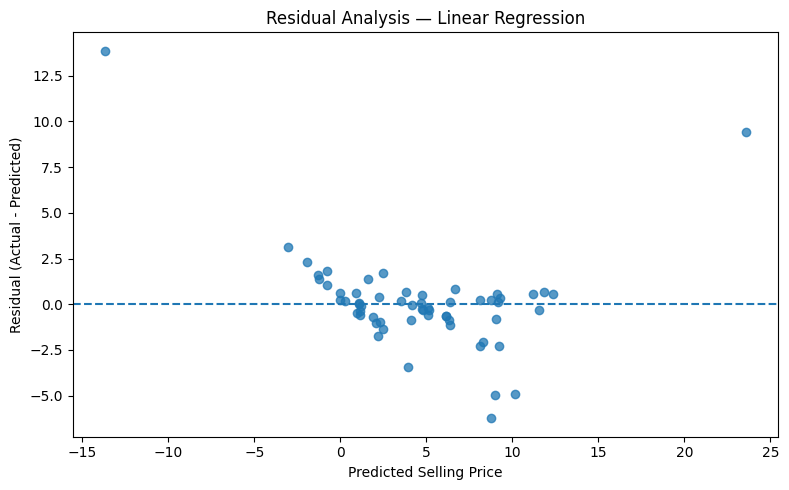

In [25]:
# plot residual
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.75)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis — Linear Regression")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "linear_regression_residuals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [27]:
# Identify the largest prediction errors

# Inspect the 10 largest absolute prediction errors
# We get the positional integer index of the largest errors first,
# then map them back to the original index of y_test (since residual_df lost the original index)
error_positions = residual_df.head(10).index
error_indices = y_test.index[error_positions]

# Align original test features with the residual table
test_features = X_test.loc[error_indices].copy()

# Join the features with their corresponding residuals by matching indices
# We temporarily set the index of the top residuals to match the mapped error_indices
top_residuals = residual_df.head(10).copy()
top_residuals.index = error_indices

error_details = test_features.join(top_residuals)

display(
    error_details.sort_values(
        "Absolute_Error", ascending=False
    )
)

error_details.to_csv(
    OUTPUT_DIR / "largest_prediction_errors.csv",
    index=True
)

print("Saved to:",
      (OUTPUT_DIR / "largest_prediction_errors.csv").resolve())

,Present_Price,Driven_kms,Car_Age,Mileage_Per_Year,Owner,Car_Name,Fuel_Type,Selling_type,Transmission,Actual_Price,Predicted_Price,Residual,Absolute_Error
194,0.520,500000,10,50000.000000,0,Activa 3g,Petrol,Individual,Automatic,0.17,-13.688622,13.858622,13.858622
63,36.230,6000,1,6000.000000,0,fortuner,Diesel,Dealer,Automatic,33.00,23.571975,9.428025,9.428025
84,23.730,142000,12,11833.333333,3,camry,Petrol,Individual,Automatic,2.50,8.737108,-6.237108,6.237108
92,22.780,89000,10,8900.000000,0,corolla altis,Petrol,Dealer,Automatic,4.00,8.967573,-4.967573,4.967573
77,22.830,80000,8,10000.000000,0,corolla altis,Petrol,Dealer,Automatic,5.25,10.161038,-4.911038,4.911038
147,0.940,24000,2,12000.000000,0,Bajaj Pulsar 220 F,Petrol,Individual,Manual,0.51,3.958076,-3.448076,3.448076
197,0.580,53000,11,4818.181818,0,Honda CB Shine,Petrol,Individual,Manual,0.12,-3.035781,3.155781,3.155781
173,0.787,75000,7,10714.285714,0,Hero Honda CBZ extreme,Petrol,Individual,Manual,0.38,-1.930686,2.310686,2.310686
59,18.610,40001,5,8000.200000,0,corolla altis,Petrol,Dealer,Manual,6.95,9.225884,-2.275884,2.275884
93,18.610,72000,6,12000.000000,0,corolla altis,Petrol,Dealer,Manual,5.85,8.120565,-2.270565,2.270565


Saved to: /content/car_price_outputs/largest_prediction_errors.csv


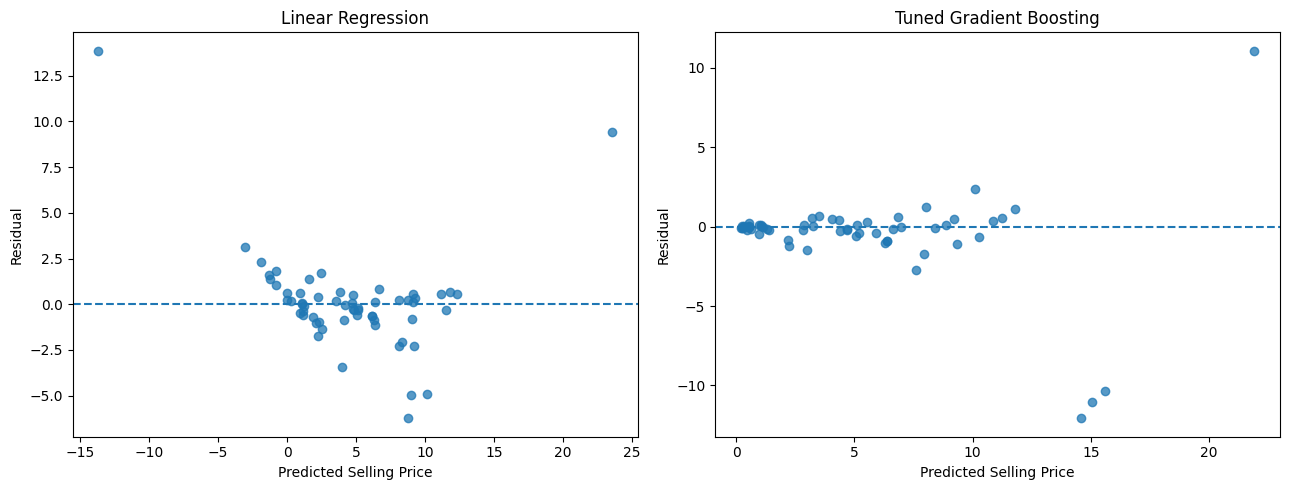

In [28]:
# Compare Linear Regression with tuned Gradient Boosting

models_to_check = {
    "Linear Regression": trained_models["Linear Regression"],
    "Tuned Gradient Boosting": gb_search.best_estimator_
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models_to_check.items()):
    pred = model.predict(X_test)
    residual = np.asarray(y_test) - pred

    ax.scatter(pred, residual, alpha=0.75)
    ax.axhline(0, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Predicted Selling Price")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "residual_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
